# 02 — Pareamento por sexo e idade

O notebook 01 mostrou que controles do ABIDE e do ADHD-200 são distinguíveis (acurácia balanceada ~0,64),
principalmente por **sexo** e **idade**. Aqui pareamos os quatro grupos e repetimos o teste.

**Método:** estratos de sexo × faixa de idade de 1 ano. Em cada estrato sorteamos o mesmo número de sujeitos de
cada grupo (TEA-ABIDE, Controle-ABIDE, Controle-ADHD200, TDAH-ADHD200). Código em `src/matching.py`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from matching import RANDOM_STATE, add_group, dataset_bias_test, match_groups, smd

FIG = ROOT / "results" / "figures"
sns.set_theme(style="whitegrid", context="notebook")
ORDEM = ["TEA (ABIDE)", "Controle (ABIDE)", "Controle (ADHD200)", "TDAH (ADHD200)"]

coorte = add_group(pd.read_csv(ROOT / "data" / "interim" / "cohort_7_21.csv"))
pareada = match_groups(coorte, age_bin=1.0, seed=RANDOM_STATE)
pd.DataFrame({"antes": coorte.grupo.value_counts(), "depois": pareada.grupo.value_counts()}).reindex(ORDEM)

,antes,depois
grupo,,
TEA (ABIDE),682,284
Controle (ABIDE),868,284
Controle (ADHD200),465,284
TDAH (ADHD200),359,284


## 1. Equilíbrio antes × depois
Diferença média padronizada (SMD) de cada grupo contra *Controle (ABIDE)*. |SMD| < 0,1 é considerado bem pareado.

In [2]:
def tabela_smd(d):
    d = d.assign(sexo_m=(d.sex == "M").astype(float))
    return pd.DataFrame({g: {c: smd(d, c, g, "Controle (ABIDE)") for c in ["age", "sexo_m", "fiq"]}
                         for g in ORDEM if g != "Controle (ABIDE)"}).T

pd.concat({"antes": tabela_smd(coorte), "depois": tabela_smd(pareada)}, axis=1).round(2)

antes              depois             
                     age sexo_m   fiq    age sexo_m   fiq
TEA (ABIDE)         0.24   0.32 -0.49   0.01    0.0 -0.36
Controle (ADHD200) -0.12  -0.51  0.09   0.01    0.0  0.29
TDAH (ADHD200)     -0.29   0.09 -0.50  -0.00    0.0 -0.41

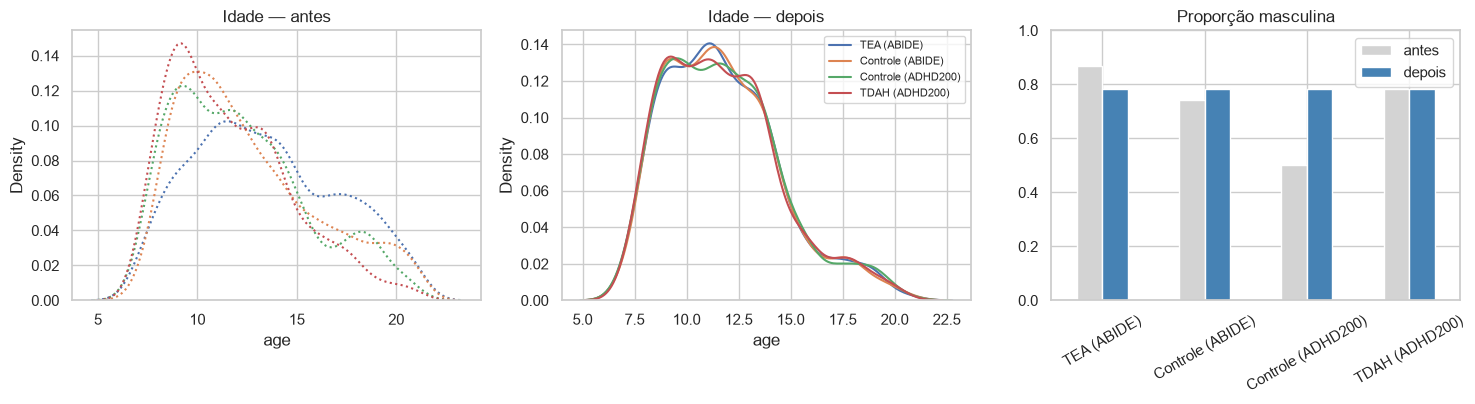

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
for d, nome, ls in [(coorte, "antes", ":"), (pareada, "depois", "-")]:
    for g, cor in zip(ORDEM, sns.color_palette("deep", 4)):
        sub = d[d.grupo == g]
        sns.kdeplot(sub.age, ax=ax[0 if nome == "antes" else 1], color=cor, ls=ls, label=g, bw_adjust=0.8)
ax[0].set_title("Idade — antes"); ax[1].set_title("Idade — depois"); ax[1].legend(fontsize=8)
masc = pd.DataFrame({"antes": coorte.groupby("grupo").sex.apply(lambda s: (s == "M").mean()),
                     "depois": pareada.groupby("grupo").sex.apply(lambda s: (s == "M").mean())}).reindex(ORDEM)
masc.plot.bar(ax=ax[2], color=["lightgray", "steelblue"]); ax[2].set_title("Proporção masculina"); ax[2].set_ylim(0, 1)
ax[2].tick_params(axis="x", rotation=30); ax[2].set_xlabel("")
fig.tight_layout(); fig.savefig(FIG / "02_pareamento_antes_depois.png", dpi=150)

## 2. Teste de viés na amostra pareada
O sorteio dentro de cada estrato é aleatório, então repetimos o pareamento com 10 sementes para ver se o
resultado é estável.

In [4]:
linhas = []
for seed in range(10):
    p = match_groups(coorte, age_bin=1.0, seed=seed)
    s = dataset_bias_test(p, seed=RANDOM_STATE)
    linhas.append({"semente": seed, "n": len(p), "acc_bal": s.mean()})
rep = pd.DataFrame(linhas)
antes = dataset_bias_test(coorte)
print(f"Sem pareamento: {antes.mean():.3f} ± {antes.std():.3f}")
print(f"Pareado (10 sementes): {rep.acc_bal.mean():.3f} ± {rep.acc_bal.std():.3f}  "
      f"[min {rep.acc_bal.min():.3f}, máx {rep.acc_bal.max():.3f}]")
rep.round(3)

Sem pareamento: 0.545 ± 0.067
Pareado (10 sementes): 0.417 ± 0.026  [min 0.384, máx 0.474]


,semente,n,acc_bal
0,0,1136,0.411
1,1,1136,0.406
2,2,1136,0.439
3,3,1136,0.384
4,4,1136,0.414
5,5,1136,0.398
6,6,1136,0.413
7,7,1136,0.474
8,8,1136,0.399
9,9,1136,0.436


## 3. Distribuição da amostra pareada por instituição

In [5]:
pd.crosstab(pareada.institution, pareada.grupo).reindex(columns=ORDEM).loc[lambda t: t.sum(axis=1) > 0]

grupo,TEA (ABIDE),Controle (ABIDE),Controle (ADHD200),TDAH (ADHD200)
institution,,,,
BNI,0,2,0,0
CALTECH,0,2,0,0
CMU,1,0,0,0
EMC,6,12,0,0
GU,35,22,0,0
IP,5,5,0,0
KKI,21,57,10,21
LEUVEN,8,8,0,0
MAX_MUN,4,3,0,0


## 4. Salvar a coorte pareada (semente 42)

In [6]:
saida = ROOT / "data" / "processed" / "cohort_matched.csv"
pareada.to_csv(saida, index=False)
print(f"{len(pareada)} sujeitos -> {saida.relative_to(ROOT)}")
pd.crosstab(pareada.dataset, pareada.diagnosis, margins=True)

1136 sujeitos -> data\processed\cohort_matched.csv


diagnosis,Controle,TDAH,TEA,All
dataset,,,,
ABIDE,284,0,284,568
ADHD200,284,284,0,568
All,568,284,284,1136


## 5. Leitura dos resultados (execução de 25/11/2026, com ABIDE II)

- **O pareamento eliminou o viés de base no fenótipo.** A acurácia balanceada para prever a base entre controles
  caiu de 0,55 para **0,42 ± 0,03** (10 sementes; acaso = 0,50). Ficar abaixo de 0,5 é um efeito conhecido da validação
  por grupos com amostras pequenas por dobra, e não indica sinal.
- **Idade e sexo equilibrados** (|SMD| ≤ 0,01).
- **Amostra pareada: 1136 sujeitos** (284 TEA, 284 TDAH, 568 controles), contra 912 sem o ABIDE II. O fator limitante
  continua sendo o TDAH (359 disponíveis).
- **O QI não foi pareado de propósito.** TEA e TDAH ficam ~0,4 DP abaixo dos controles (esperado). Controles do ADHD-200
  ficam 0,29 DP acima dos do ABIDE (diferença de recrutamento, não suficiente para denunciar a base).
- A amostra é majoritariamente masculina, de 7–21 anos.

**Próximo passo:** baseline em `data/processed/cohort_matched.csv` (notebook 03).